# Coursework 2 Part 1
**Replace CID in the file name with your CID**

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Importing losses, activation functions and layers from PyTorch
from torch.nn import Sequential, CrossEntropyLoss, Conv1d, MaxPool1d, Flatten, Linear, ReLU, Softmax, Parameter
from torch.nn import Conv2d, MaxPool2d, ConvTranspose2d, MSELoss
from torch.utils.data import TensorDataset, DataLoader

SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# Outline


- [Task 1](#task-1): Dimensionality Reduction and Regression with Convolutional Neural Networks - CNNs
 <a name="index-task-1"></a>
  - [(1.1)](#task-11) <a name="index-task-11"></a>
  - [(1.2)](#task-12) <a name="index-task-12"></a>
- [Task 2](#task-2): Graph-based learning <a name="index-task-2"></a>
  - [(2.1)](#task-21) <a name="index-task-21"></a>
  - [(2.2)](#task-22)  <a name="index-task-22"></a>

<a name="task-1"></a>

# Task 1: Dimensionality Reduction and Regression with Convolutional Neural Networks - CNNs [(index)](#index-task-1)

<a name="task-11"></a>

## (1.1) [(index)](#index-task-11)

In [21]:
import pandas as pd
PATH=''
dataset = pd.read_csv(PATH + "gene_expression_transcriptomic_data.csv")

data_train = dataset.iloc[:1848, :100].values # extract the first 1848 rows and 100 columns
data_val = dataset.iloc[1848:1848+264, :100].values # extract the first 264 rows and 100 columns
data_test = dataset.iloc[1848+264:1848+264+529, :100].values # extract the first 529 rows and 100 columns

treatment_train = dataset.iloc[:, 101].values[:1848, ] # extract the corresponding 1848 treatment labels
treatment_val = dataset.iloc[:, 101].values[1848:1848+264, ] # extract the corresponding 264 treatment labels
treatment_test = dataset.iloc[:, 101].values[1848+264:1848+264+529] # extract the corresponding 529 treatment labels

classes=[0,1]

X_train = data_train.reshape(data_train.shape[0], 10, 10)
X_val = data_val.reshape(data_val.shape[0], 10, 10)
X_test = data_test.reshape(data_test.shape[0], 10, 10)
X_train = X_train[:, np.newaxis, :, :]
X_val = X_val[:, np.newaxis, :, :]
X_test = X_test[:, np.newaxis, :, :]

In [35]:
# Numpy arrays to PyTorch tensors
x_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(treatment_train, dtype=torch.float32)
x_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(treatment_val, dtype=torch.float32)

# Creating training and validation datasets
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)

# Creating corresponding DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [36]:
len(train_loader.dataset)

1848

In [82]:
def get_model(x_train, n_filters, k, pool_size, stride_pool):
    """
    CNN model in PyTorch:
    - Layers are Conv1d(+ReLU), MaxPool1d, Flatten and Linear(+Softmax).
    - It features an Adam optimiser and CrossEntropyLoss criterion.

    Parameters:
        x_train (np.ndarray): Training data
        n_filters (int): Number of filters to be used in the convolutional layer
        k (int): Kernel size in the convolutional layer
        pool_size (int): MaxPool1d window size
        stride_pool (int): Stride of the MaxPool1d sliding window
        classes (List): Output classes

    Returns:
        Model, criterion and optimiser.

    """

    model = Sequential(
        Conv2d(in_channels=1, out_channels=n_filters, kernel_size=k, padding=1),
        ReLU(),
        MaxPool2d(kernel_size=pool_size, stride=stride_pool),
        Conv2d(in_channels=n_filters, out_channels=n_filters, kernel_size=k, padding=1),
        ReLU(),
        ConvTranspose2d(in_channels=n_filters, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1),
        ReLU()
    )

    criterion = torch.nn.CrossEntropyLoss() ## <-- SOLUTION
    optimiser = torch.optim.Adam(model.parameters()) ## <-- SOLUTION

    return model, criterion, optimiser


In [83]:
n_filters = 8
k = 3
pool_size = 2
stride_pool = 2

model, criterion, optimiser = get_model(X_train, n_filters, k, pool_size, stride_pool) ## <-- SOLUTION
print(model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): ConvTranspose2d(8, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (6): ReLU()
)


In [84]:
def compute_mse_loss(x, x_hat):
    mse = torch.mean((x - x_hat) ** 2)
    return mse  



In [85]:
class EarlyStopping:
    """
    EarlyStopping class.

    Attributes:
        max_patience (int): Amount of epochs with no improvement after which training is stopped.
        patience (int): Stores the number of epochs with no improvement.
        best_valid_loss (float): Stores the current value of the best (minimum) validation loss.
        early_stop (bool) True if training needs to be stopped due to the early stopping condition being met.

    Methods:
        step(val_loss):
            Checks current state after an epoch and updates best_loss, patience and early_stop accordingly.
    """

    def __init__(self, max_patience=5):
        self.max_patience = max_patience
        self.patience = 0
        self.best_valid_loss = float('inf') ## <-- SOLUTION
        self.early_stop = False

    def step(self, val_loss):
        if val_loss < self.best_valid_loss:  ## <-- SOLUTION
            self.best_valid_loss = val_loss  ## <-- SOLUTION
            self.patience = 0  ## <-- SOLUTION
        else:
            self.patience += 1
            if self.patience >= self.max_patience:
                self.early_stop = True

In [86]:
def training_loop(train_loader, val_loader, max_num_epochs=100, max_patience=5):
    """
    Training loop with early stopping to monitor the validation accuracy.

    Parameters:
        train_loader (torch.utils.data.DataLoader): Training DataLoader
        val_loader (torch.utils.data.DataLoader): Validation DataLoader
        max_num_epochs (int): Maximum number of epochs
        max_patience (int): max_patience attribute of the EarlyStopping class

    Returns:
        Model, criterion and optimiser.

    """

    history = {'training_loss': [], 'validation_loss': [], 'training_accuracy': [], 'validation_accuracy': []}
    early_stopping = EarlyStopping(max_patience=max_patience)

    for epoch in range(max_num_epochs):
        # Training Phase
        model.train()  # Ensure model is in training mode
        total_train_loss = 0.0
        for inputs, labels in train_loader:
            if inputs.ndim == 3:
                inputs = inputs.unsqueeze(1)
            optimiser.zero_grad()  # Reset gradients
            outputs = model(inputs)  # Forward pass
            loss = compute_mse_loss(inputs, outputs)  # Compute reconstruction loss
            loss.backward()  # Backpropagate
            optimiser.step()  # Update parameters
            total_train_loss += loss.item() * inputs.size(0)
        avg_train_loss = total_train_loss / len(train_loader.dataset)
        history['training_loss'].append(avg_train_loss)
        
        # Validation Phase
        model.eval()  # Set model to evaluation mode
        total_val_loss = 0.0
        with torch.no_grad():
            for inputs_val, labels in val_loader:
                if inputs_val.ndim == 3:
                    inputs_val = inputs_val.unsqueeze(1)
                outputs_val = model(inputs_val)
                loss_val = compute_mse_loss(inputs_val, outputs_val)
                total_val_loss += loss_val.item() * inputs_val.size(0)
        avg_val_loss = total_val_loss / len(val_loader.dataset)
        history['validation_loss'].append(avg_val_loss)
        
        print(f"Epoch {epoch+1}/{max_num_epochs}: Training Loss: {avg_train_loss:.4f}, Validation Loss: {avg_val_loss:.4f}")
        
        # Early stopping check
        early_stopping.step(avg_val_loss)
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

    return history

In [87]:
# Calling the training loop
max_num_epochs = 100
max_patience = 5

history = training_loop(train_loader, val_loader, max_num_epochs, max_patience)

Epoch 1/100: Training Loss: 2.7390, Validation Loss: 1.8781
Epoch 2/100: Training Loss: 1.4279, Validation Loss: 1.2067
Epoch 3/100: Training Loss: 1.1159, Validation Loss: 1.0248
Epoch 4/100: Training Loss: 1.0138, Validation Loss: 0.9782
Epoch 5/100: Training Loss: 0.9773, Validation Loss: 0.9482
Epoch 6/100: Training Loss: 0.9505, Validation Loss: 0.9260
Epoch 7/100: Training Loss: 0.9290, Validation Loss: 0.9083
Epoch 8/100: Training Loss: 0.9108, Validation Loss: 0.8947
Epoch 9/100: Training Loss: 0.8967, Validation Loss: 0.8833
Epoch 10/100: Training Loss: 0.8857, Validation Loss: 0.8735
Epoch 11/100: Training Loss: 0.8751, Validation Loss: 0.8628
Epoch 12/100: Training Loss: 0.8642, Validation Loss: 0.8533
Epoch 13/100: Training Loss: 0.8543, Validation Loss: 0.8444
Epoch 14/100: Training Loss: 0.8446, Validation Loss: 0.8352
Epoch 15/100: Training Loss: 0.8347, Validation Loss: 0.8252
Epoch 16/100: Training Loss: 0.8245, Validation Loss: 0.8167
Epoch 17/100: Training Loss: 0.81

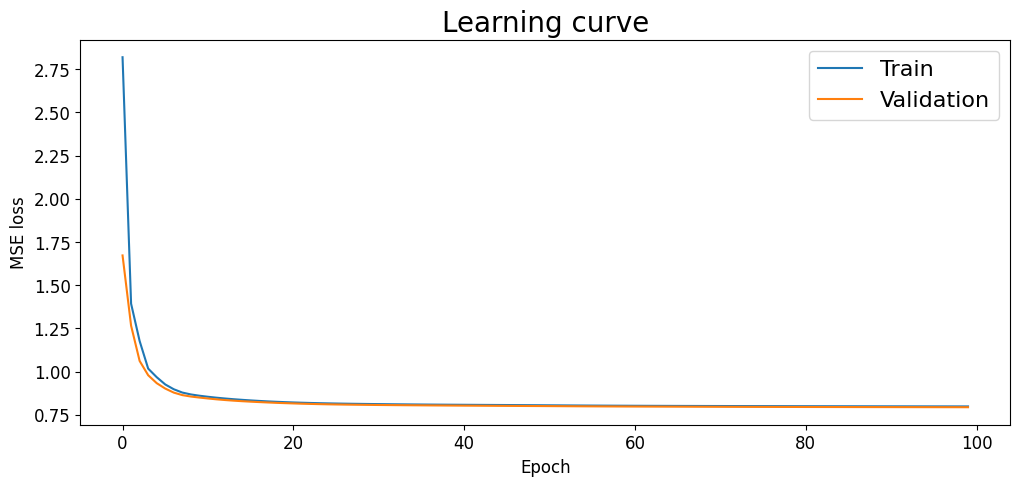

In [70]:
# Plot the learning curves

fig = plt.figure(figsize=(12, 5))

plt.plot(history['training_loss'], label='Train')
plt.plot(history['validation_loss'], label='Validation')
plt.xlabel('Epoch', size=12)
plt.ylabel('MSE loss', size=12)
plt.title('Learning curve')
plt.legend()

<a name="task-12"></a>

## (1.2) [(index)](#index-task-12)

<a name="task-2"></a>

# Task 2: Graph-based learning [(index)](#index-task-2)

In [ ]:
PATH='/content/drive/MyDrive/data_science_cw2/' # Put your path to the file here

# Dataset upload #
import pandas as pd
dataset = pd.read_csv(PATH + "gene_expression_transcriptomic_data.csv")

X = dataset.iloc[:400, :10].values # extract the first 400 rows and 10 columns
treatment = dataset.iloc[:, 101].values[:400, ] # extract the corresponding 400 treatment labels

<a name="task-21"></a>

## (2.1) [(index)](#index-task-21)

<a name="task-22"></a>

## (2.2) [(index)](#index-task-22)